Set Up the Environment

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps
from tqdm import tqdm
from collections import Counter

# Charger les IDs de la KB
with open("../splits/splits_all.json", "r") as f:
    splits = json.load(f)

kb_ids = splits["kb"]

# Chemin des images originales
IMAGE_FOLDER = "../data/images/train"

print("Nombre d'images dans KB :", len(kb_ids))
print("Dossier des images existe :", os.path.exists(IMAGE_FOLDER))

Nombre d'images dans KB : 10000
Dossier des images existe : True


Check for Missing and Corrupted Images

In [2]:
missing_images = []
corrupted_images = []
valid_images = []

for iid in tqdm(kb_ids):

    image_name = f"{int(iid):012d}.jpg"
    image_path = os.path.join(IMAGE_FOLDER, image_name)

    if not os.path.exists(image_path):
        missing_images.append(iid)
        continue

    try:
        with Image.open(image_path) as img:
            img.verify()

        valid_images.append(iid)

    except Exception:
        corrupted_images.append(iid)

print("Images valides :", len(valid_images))
print("Images manquantes :", len(missing_images))
print("Images corrompues :", len(corrupted_images))

100%|██████████| 10000/10000 [00:12<00:00, 771.60it/s]

Images valides : 10000
Images manquantes : 0
Images corrompues : 0


Check Image Formats and Dimensions(extration)

In [3]:
formats = Counter()
dimensions = Counter()
modes = Counter()

for iid in tqdm(valid_images):

    image_name = f"{int(iid):012d}.jpg"
    image_path = os.path.join(IMAGE_FOLDER, image_name)

    with Image.open(image_path) as img:
        formats[img.format] += 1
        dimensions[img.size] += 1
        modes[img.mode] += 1

print("Formats :", formats)
print("\nModes :", modes)
print("\nDimensions les plus fréquentes :")
print(dimensions.most_common(10))

100%|██████████| 10000/10000 [00:06<00:00, 1492.78it/s]


Formats : Counter({'JPEG': 10000})

Modes : Counter({'RGB': 9984, 'L': 16})

Dimensions les plus fréquentes :
[((640, 480), 2136), ((640, 427), 1218), ((480, 640), 699), ((640, 426), 470), ((500, 375), 411), ((427, 640), 343), ((640, 428), 304), ((640, 425), 297), ((612, 612), 199), ((375, 500), 182)]


some images

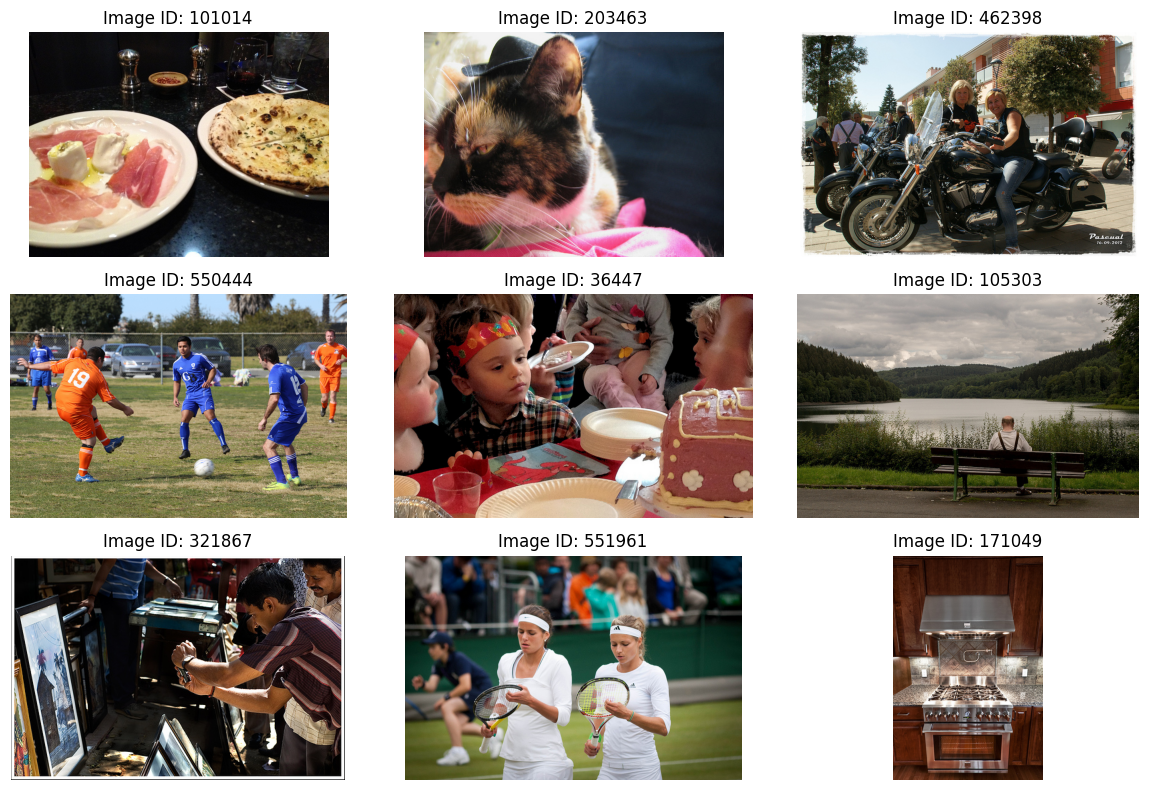

In [4]:
sample_ids = valid_images[:9]

plt.figure(figsize=(12, 8))

for i, iid in enumerate(sample_ids):
    image_name = f"{int(iid):012d}.jpg"
    image_path = os.path.join(IMAGE_FOLDER, image_name)

    with Image.open(image_path) as img:
        plt.subplot(3, 3, i + 1)
        plt.imshow(img.convert("RGB"))
        plt.title(f"Image ID: {iid}")
        plt.axis("off")

plt.tight_layout()
plt.show()

Verify Image Formats and Dimensions

In [5]:
from collections import Counter

formats = Counter()
dimensions = Counter()
modes = Counter()

for iid in tqdm(valid_images):

    image_name = f"{int(iid):012d}.jpg"
    image_path = os.path.join(IMAGE_FOLDER, image_name)

    with Image.open(image_path) as img:
        formats[img.format] += 1
        dimensions[img.size] += 1
        modes[img.mode] += 1

print("Formats :", formats)
print("\nModes :", modes)
print("\nDimensions les plus fréquentes :")
print(dimensions.most_common(10))

100%|██████████| 10000/10000 [00:06<00:00, 1473.06it/s]

Formats : Counter({'JPEG': 10000})

Modes : Counter({'RGB': 9984, 'L': 16})

Dimensions les plus fréquentes :
[((640, 480), 2136), ((640, 427), 1218), ((480, 640), 699), ((640, 426), 470), ((500, 375), 411), ((427, 640), 343), ((640, 428), 304), ((640, 425), 297), ((612, 612), 199), ((375, 500), 182)]


correct exif and convertir to RGB

In [ ]:
# Dossier de destination
OUTPUT_FOLDER = "../data/processed/images"

os.makedirs(OUTPUT_FOLDER, exist_ok=True)

processed_count = 0
errors = []

for iid in tqdm(valid_images):

    image_name = f"{int(iid):012d}.jpg"

    input_path = os.path.join(IMAGE_FOLDER, image_name)
    output_path = os.path.join(OUTPUT_FOLDER, image_name)

    try:
        with Image.open(input_path) as img:

            # corriger l'orientation EXIF
            img = ImageOps.exif_transpose(img)

            # Convert to RGB
            img = img.convert("RGB")

            # Save the copied image
            img.save(output_path, format="JPEG", quality=95)

            processed_count += 1

    except Exception as e:
        errors.append({
            "image_id": iid,
            "error": str(e)
        })

print("Images prétraitées :", processed_count)
print("Erreurs :", len(errors))

100%|██████████| 10000/10000 [01:09<00:00, 143.92it/s]

Images prétraitées : 10000
Erreurs : 0


verefy the images

In [7]:
processed_modes = Counter()

for iid in tqdm(valid_images):

    image_name = f"{int(iid):012d}.jpg"
    image_path = os.path.join(OUTPUT_FOLDER, image_name)

    if os.path.exists(image_path):
        with Image.open(image_path) as img:
            processed_modes[img.mode] += 1

print("Modes après preprocessing :", processed_modes)
print("Nombre de fichiers :", len(os.listdir(OUTPUT_FOLDER)))

100%|██████████| 10000/10000 [01:46<00:00, 93.57it/s]

Modes après preprocessing : Counter({'RGB': 10000})
Nombre de fichiers : 10000


Resizing

In [8]:
from collections import Counter

processed_dimensions = Counter()

for iid in tqdm(valid_images):
    image_name = f"{int(iid):012d}.jpg"
    image_path = os.path.join(OUTPUT_FOLDER, image_name)

    with Image.open(image_path) as img:
        processed_dimensions[img.size] += 1

print("Dimensions les plus fréquentes :")
print(processed_dimensions.most_common(10))

100%|██████████| 10000/10000 [00:08<00:00, 1181.58it/s]

Dimensions les plus fréquentes :
[((640, 480), 2136), ((640, 427), 1218), ((480, 640), 699), ((640, 426), 470), ((500, 375), 411), ((427, 640), 343), ((640, 428), 304), ((640, 425), 297), ((612, 612), 199), ((375, 500), 182)]


In [9]:
RESIZE_SIZE = (	384, 512)

RESIZED_FOLDER = "../data/processed/images_resized"
os.makedirs(RESIZED_FOLDER, exist_ok=True)

resized_count = 0
resize_errors = []

for iid in tqdm(valid_images):

    image_name = f"{int(iid):012d}.jpg"

    input_path = os.path.join(OUTPUT_FOLDER, image_name)
    output_path = os.path.join(RESIZED_FOLDER, image_name)

    try:
        with Image.open(input_path) as img:

            # Redimensionner sans déformer
            img.thumbnail(
                RESIZE_SIZE,
                Image.Resampling.LANCZOS
            )

            img.save(
                output_path,
                format="JPEG",
                quality=95
            )

            resized_count += 1

    except Exception as e:
        resize_errors.append({
            "image_id": iid,
            "error": str(e)
        })

print("Images redimensionnées :", resized_count)
print("Erreurs :", len(resize_errors))

100%|██████████| 10000/10000 [02:05<00:00, 79.98it/s]

Images redimensionnées : 10000
Erreurs : 0


verification

In [10]:
resized_dimensions = Counter()

for iid in tqdm(valid_images):

    image_name = f"{int(iid):012d}.jpg"
    image_path = os.path.join(RESIZED_FOLDER, image_name)

    with Image.open(image_path) as img:
        resized_dimensions[img.size] += 1

print("Nombre de fichiers :", len(os.listdir(RESIZED_FOLDER)))
print("Dimensions :", resized_dimensions.most_common(10))

print(
    "Toutes les images respectent les limites :",
    all(w <= 384 and h <= 512 for w, h in resized_dimensions)
)

100%|██████████| 10000/10000 [01:41<00:00, 98.80it/s]


Nombre de fichiers : 10000
Dimensions : [((384, 288), 2570), ((384, 256), 1841), ((384, 512), 701), ((384, 257), 444), ((342, 512), 418), ((384, 384), 357), ((384, 255), 341), ((375, 500), 182), ((384, 254), 157), ((341, 512), 152)]
Toutes les images respectent les limites : True
